# Implementación de un Modelo Transformer para Series de Tiempo

## Descripción

Este notebook desarrolla una implementación básica de la arquitectura Transformer aplicada al análisis y predicción de series de tiempo mediante Python, TensorFlow y Keras.

El propósito es comprender el funcionamiento de los mecanismos de Self-Attention, Multi-Head Attention y codificación posicional, identificando cómo estos componentes permiten procesar secuencias temporales y reconocer relaciones entre diferentes posiciones de entrada.

## Objetivos

- Comprender la arquitectura básica de un Transformer.
- Implementar codificación posicional.
- Construir un mecanismo Multi-Head Self-Attention.
- Implementar bloques de procesamiento Transformer.
- Entrenar un modelo de predicción de series temporales.
- Evaluar los resultados mediante métricas de error.
- Analizar los patrones de atención generados.

## Tecnologías utilizadas

Python, TensorFlow, Keras, NumPy, Pandas, Matplotlib y Scikit-learn.

In [1]:
# Importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("TensorFlow:", tf.__version__)
print("Librerías importadas correctamente.")

TensorFlow: 2.21.0
Librerías importadas correctamente.


## 1. Generación de datos

Se genera una serie de tiempo sintética compuesta por una tendencia general, componentes estacionales y pequeñas variaciones aleatorias.

Se utiliza el mismo conjunto de datos del notebook anterior para garantizar condiciones equivalentes en la comparación entre el mecanismo de atención básico y la arquitectura Transformer.

In [2]:
# Generación de datos sintéticos

np.random.seed(42)

tiempo = np.arange(1500)

tendencia = 0.005 * tiempo

estacionalidad = (
    0.8 * np.sin(2 * np.pi * tiempo / 50) +
    0.4 * np.sin(2 * np.pi * tiempo / 20)
)

ruido = np.random.normal(0, 0.15, 1500)

serie = tendencia + estacionalidad + ruido

datos = pd.DataFrame({
    "Tiempo": tiempo,
    "Valor": serie
})

print(datos.head())
print("\nCantidad de registros:", len(datos))

   Tiempo     Valor
0       0  0.074507
1       1  0.208134
2       2  0.541219
3       3  0.861561
4       4  0.750703

Cantidad de registros: 1500


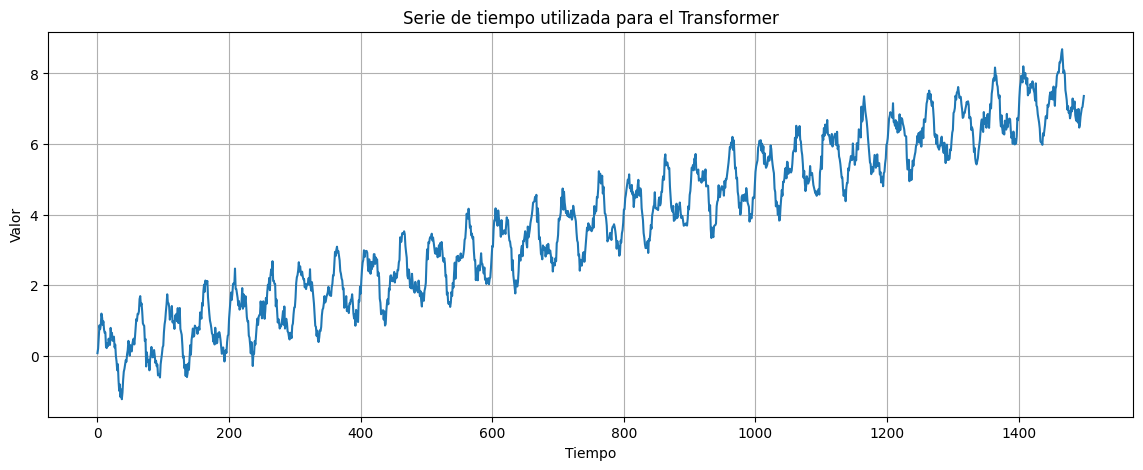

In [3]:
# Visualización de la serie temporal

plt.figure(figsize=(14, 5))

plt.plot(datos["Tiempo"], datos["Valor"])

plt.title("Serie de tiempo utilizada para el Transformer")
plt.xlabel("Tiempo")
plt.ylabel("Valor")

plt.grid(True)
plt.show()

## 2. Preparación de los datos

Se realiza una división cronológica de los datos, destinando el 80 % al entrenamiento y el 20 % restante a las pruebas.

Posteriormente, se aplica MinMaxScaler para normalizar los valores entre 0 y 1. El escalador se ajusta únicamente con los datos de entrenamiento para evitar la filtración de información del conjunto de prueba.

In [4]:
# División de los datos

valores = datos["Valor"].values.reshape(-1, 1)

limite = int(len(valores) * 0.80)

train_data = valores[:limite]
test_data = valores[limite:]

# Normalización

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

print("Datos de entrenamiento:", len(train_scaled))
print("Datos de prueba:", len(test_scaled))

Datos de entrenamiento: 1200
Datos de prueba: 300


## 3. Construcción de secuencias

Se utiliza una ventana temporal de 30 posiciones para construir las secuencias de entrada del Transformer.

Cada secuencia representa un conjunto de valores históricos que el modelo utiliza para aprender relaciones temporales y generar una predicción del siguiente valor.

In [5]:
# Función para crear secuencias

def crear_secuencias(data, ventana=30):

    X, y = [], []

    for i in range(len(data) - ventana):

        X.append(data[i:i + ventana])
        y.append(data[i + ventana])

    return np.array(X), np.array(y)


# Datos de entrenamiento

X_train, y_train = crear_secuencias(train_scaled)

# Datos de prueba con contexto anterior

test_completo = np.concatenate(
    [train_scaled[-30:], test_scaled],
    axis=0
)

X_test, y_test = crear_secuencias(test_completo)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1170, 30, 1)
y_train: (1170, 1)
X_test: (300, 30, 1)
y_test: (300, 1)


## 4. Proyección de entrada

Se implementa una capa de proyección mediante Dense para transformar los valores de la serie temporal en vectores de 64 dimensiones.

Esta representación permite que el modelo procese la información mediante las capas de atención y las redes neuronales internas de la arquitectura Transformer.

In [6]:
# Proyección de entrada

dimension_modelo = 64

proyeccion = tf.keras.layers.Dense(
    dimension_modelo
)

print("Dimensión del modelo:", dimension_modelo)

Dimensión del modelo: 64


## 4. Codificación posicional

La codificación posicional permite incorporar información sobre la ubicación de cada elemento dentro de una secuencia.

En esta implementación se utiliza una capa Embedding entrenable que asigna una representación vectorial a cada posición temporal. Posteriormente, esta representación se suma a los vectores de entrada para proporcionar información sobre el orden de los datos.

In [7]:
# Capa de codificación posicional

class PositionalEncoding(tf.keras.layers.Layer):

    def __init__(self, max_length, dimension):
        super().__init__()

        self.embedding = tf.keras.layers.Embedding(
            input_dim=max_length,
            output_dim=dimension
        )

    def call(self, inputs):

        posiciones = tf.range(
            start=0,
            limit=tf.shape(inputs)[1]
        )

        codificacion = self.embedding(posiciones)

        return inputs + codificacion


print("Capa de codificación posicional creada.")

Capa de codificación posicional creada.


## 5. Implementación de Multi-Head Self-Attention

Se utiliza la capa MultiHeadAttention de TensorFlow y Keras para implementar el mecanismo de atención múltiple.

El modelo utiliza cuatro cabezas de atención, lo que permite analizar diferentes relaciones entre las posiciones de una secuencia temporal.

Se utiliza Self-Attention porque las consultas (Queries), claves (Keys) y valores (Values) se obtienen de la misma secuencia de entrada.

La atención permite construir representaciones contextualizadas de los datos temporales.

In [8]:
# Implementación de Multi-Head Self-Attention

class TransformerEncoder(tf.keras.layers.Layer):

    def __init__(
        self,
        dimension,
        num_heads,
        ff_dim,
        dropout=0.1
    ):
        super().__init__()

        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=dimension // num_heads,
            dropout=dropout
        )

        self.dropout1 = tf.keras.layers.Dropout(dropout)

        self.norm1 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(
                ff_dim,
                activation="relu"
            ),
            tf.keras.layers.Dense(dimension)
        ])

        self.dropout2 = tf.keras.layers.Dropout(dropout)

        self.norm2 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

    def call(self, inputs, training=False):

        # Self-Attention

        salida_atencion, pesos = self.attention(
            query=inputs,
            key=inputs,
            value=inputs,
            return_attention_scores=True,
            training=training
        )

        salida_atencion = self.dropout1(
            salida_atencion,
            training=training
        )

        # Primera conexión residual y normalización

        x = self.norm1(
            inputs + salida_atencion
        )

        # Red neuronal Feed Forward

        salida_ffn = self.ffn(x)

        salida_ffn = self.dropout2(
            salida_ffn,
            training=training
        )

        # Segunda conexión residual y normalización

        salida = self.norm2(
            x + salida_ffn
        )

        return salida, pesos


print("Bloque Transformer creado correctamente.")

Bloque Transformer creado correctamente.


## 6. Construcción de la arquitectura Transformer

Se construye un modelo Transformer básico compuesto por una capa de proyección de entrada, codificación posicional y un bloque Transformer Encoder.

Posteriormente, se utiliza una capa GlobalAveragePooling1D para resumir la información contextualizada de la secuencia.

Finalmente, una capa Dense con una neurona genera la predicción del siguiente valor temporal.

In [9]:
# Construcción del modelo Transformer

entrada = tf.keras.Input(
    shape=(30, 1)
)

# Proyección de entrada

x = tf.keras.layers.Dense(
    64
)(entrada)

# Codificación posicional

posicion = PositionalEncoding(
    max_length=30,
    dimension=64
)

x = posicion(x)

# Bloque Transformer

bloque_transformer = TransformerEncoder(
    dimension=64,
    num_heads=4,
    ff_dim=128,
    dropout=0.1
)

x, pesos_atencion = bloque_transformer(x)

# Resumen de la secuencia

x = tf.keras.layers.GlobalAveragePooling1D()(x)

# Capa de salida

salida = tf.keras.layers.Dense(1)(x)

# Crear modelo

modelo_transformer = tf.keras.Model(
    inputs=entrada,
    outputs=salida
)

# Compilación

modelo_transformer.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Resumen

modelo_transformer.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30, 64)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ (None, 30, 64)         │         1,920 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder             │ [(None, 30, 64),       │        33,472 │
│ (TransformerEncoder)            │ (None, 4, 30, 30)]     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,585 (139.00 KB)

 Trainable params: 35,585 (139.00 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Entrenamiento del modelo Transformer

El modelo se entrena utilizando el optimizador Adam y la función de pérdida Mean Squared Error (MSE).

Se establecen 30 épocas de entrenamiento y un tamaño de lote de 32 muestras.

Se utiliza una división interna del conjunto de entrenamiento para validar el comportamiento del modelo durante el aprendizaje, manteniendo los datos de prueba separados para la evaluación final.

In [10]:
# Entrenamiento del Transformer

historial_transformer = modelo_transformer.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

Epoch 1/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - loss: 0.1498 - mae: 0.2946 - val_loss: 0.0225 - val_mae: 0.1320
Epoch 2/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.1263 - mae: 0.2735 - val_loss: 0.0305 - val_mae: 0.1559
Epoch 3/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0121 - mae: 0.0889 - val_loss: 0.0064 - val_mae: 0.0649
Epoch 4/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0176 - mae: 0.1028 - val_loss: 0.0078 - val_mae: 0.0700
Epoch 5/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0130 - mae: 0.0902 - val_loss: 0.0061 - val_mae: 0.0637
Epoch 6/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0128 - mae: 0.0898 - val_loss: 0.0059 - val_mae: 0.0627
Epoch 7/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0136 - mae: 0.0945 - val_loss: 0.0068 - val_mae: 0.0695
Epoch 8/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0134 - mae: 0.0927 - val_loss: 0.0060 - val_mae: 0.0658
Epoch 9/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.014

## 8. Visualización del entrenamiento

Se representan gráficamente las pérdidas obtenidas durante el entrenamiento y la validación.

Esta visualización permite analizar la evolución del error y observar si el modelo está aprendiendo los patrones presentes en la serie temporal.

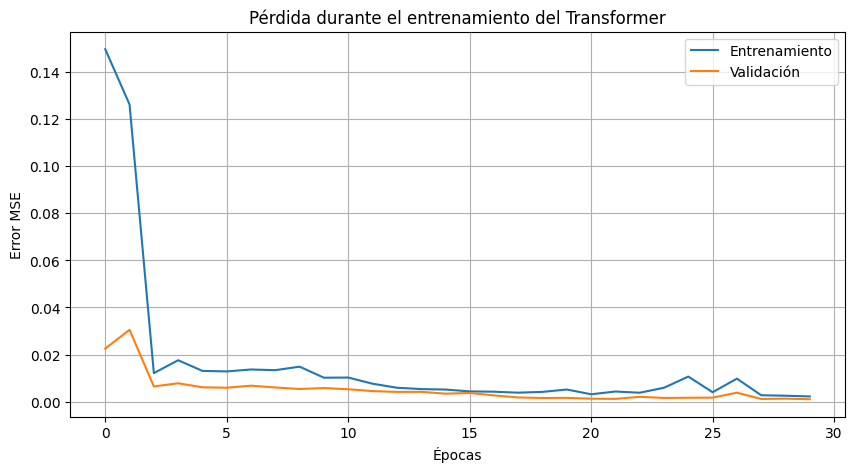

In [11]:
# Gráfica de pérdida

plt.figure(figsize=(10, 5))

plt.plot(
    historial_transformer.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    historial_transformer.history["val_loss"],
    label="Validación"
)

plt.title("Pérdida durante el entrenamiento del Transformer")
plt.xlabel("Épocas")
plt.ylabel("Error MSE")

plt.legend()
plt.grid(True)

plt.show()

## 9. Evaluación del modelo

Una vez finalizado el entrenamiento, se utiliza el conjunto de prueba para evaluar la capacidad de generalización del Transformer.

Se realizan predicciones sobre las secuencias temporales y se transforman nuevamente los resultados a su escala original para facilitar la interpretación de los errores.

In [12]:
# Generar predicciones

predicciones_transformer = modelo_transformer.predict(
    X_test
)

# Recuperar escala original

predicciones_reales = scaler.inverse_transform(
    predicciones_transformer
)

valores_reales = scaler.inverse_transform(
    y_test
)

# Calcular métricas

mae_transformer = mean_absolute_error(
    valores_reales,
    predicciones_reales
)

rmse_transformer = np.sqrt(
    mean_squared_error(
        valores_reales,
        predicciones_reales
    )
)

print("RESULTADOS DEL TRANSFORMER")
print("--------------------------")

print("MAE:", mae_transformer)
print("RMSE:", rmse_transformer)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 179ms/step
RESULTADOS DEL TRANSFORMER
--------------------------
MAE: 0.671685777535659
RMSE: 0.7725855216565598


## 10. Comparación entre valores reales y predicciones

Se realiza una representación gráfica de los valores reales de la serie temporal y las predicciones generadas por el Transformer.

Esta comparación permite observar visualmente la capacidad del modelo para reconocer los patrones y tendencias presentes en los datos.

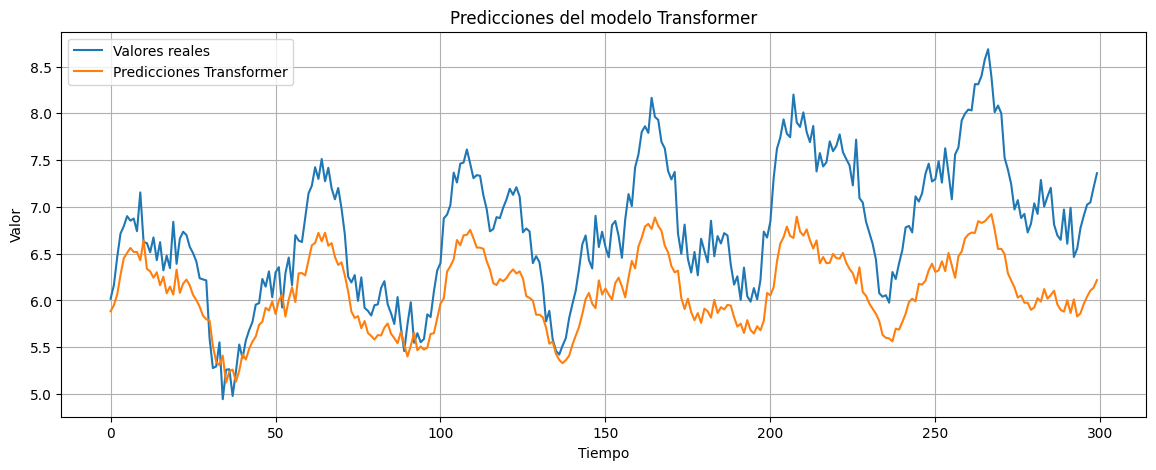

In [13]:
# Gráfica de predicciones

plt.figure(figsize=(14, 5))

plt.plot(
    valores_reales,
    label="Valores reales"
)

plt.plot(
    predicciones_reales,
    label="Predicciones Transformer"
)

plt.title("Predicciones del modelo Transformer")
plt.xlabel("Tiempo")
plt.ylabel("Valor")

plt.legend()
plt.grid(True)

plt.show()

## 11. Visualización de los pesos de atención

Se extraen los pesos generados por el mecanismo Multi-Head Self-Attention para analizar las relaciones que establece el modelo entre las diferentes posiciones de la secuencia temporal.

La arquitectura utiliza cuatro cabezas de atención, cada una capaz de aprender diferentes relaciones entre los valores históricos.

In [14]:
# Crear un modelo auxiliar para extraer los pesos

modelo_visualizacion = tf.keras.Model(
    inputs=entrada,
    outputs=pesos_atencion
)

# Obtener los pesos de una secuencia de prueba

pesos = modelo_visualizacion.predict(
    X_test[:1]
)

print("Dimensiones de los pesos:", pesos.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 536ms/step
Dimensiones de los pesos: (1, 4, 30, 30)


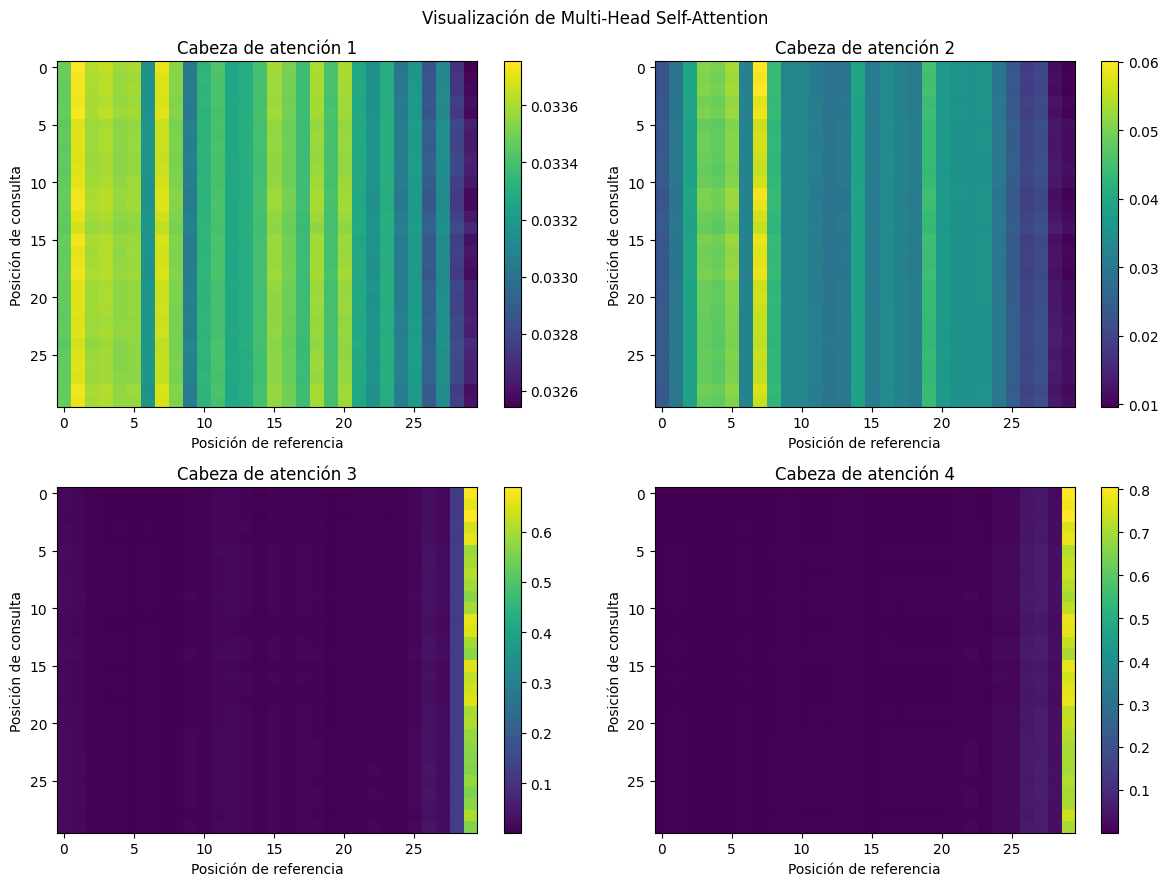

In [15]:
# Visualización de las cuatro cabezas de atención

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9)
)

for i, ax in enumerate(axes.flat):

    imagen = ax.imshow(
        pesos[0, i],
        cmap="viridis",
        aspect="auto"
    )

    ax.set_title(f"Cabeza de atención {i + 1}")
    ax.set_xlabel("Posición de referencia")
    ax.set_ylabel("Posición de consulta")

    fig.colorbar(imagen, ax=ax)

plt.suptitle("Visualización de Multi-Head Self-Attention")

plt.tight_layout()
plt.show()

## 12. Conclusiones

Durante esta práctica se implementó una arquitectura Transformer básica utilizando TensorFlow y Keras para realizar predicciones sobre una serie de tiempo sintética.

La arquitectura integró diferentes componentes, entre ellos la proyección de entrada, la codificación posicional, el mecanismo Multi-Head Self-Attention, las conexiones residuales, la normalización y las redes Feed Forward.

El mecanismo de atención permitió establecer relaciones entre diferentes posiciones de la secuencia temporal, mientras que la codificación posicional proporcionó información sobre el orden de los datos.

Durante el entrenamiento se observó la evolución de las funciones de pérdida y las métricas de error. Posteriormente, se evaluó el modelo utilizando datos de prueba mediante MAE y RMSE.

Finalmente, la visualización de los pesos de atención permitió analizar las relaciones aprendidas por las diferentes cabezas de atención.

Esta implementación permitió comprender la estructura de los Transformers y reconocer su utilidad para procesar información secuencial y desarrollar modelos de predicción.